# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import UBCDataset
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor
from aitlas.utils import image_loader

## Load the dataset

In [66]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ubc/train/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/ubc/annotations/roof_coarse_train.json",
}

dataset = UBCDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 560


## Show images from the dataset

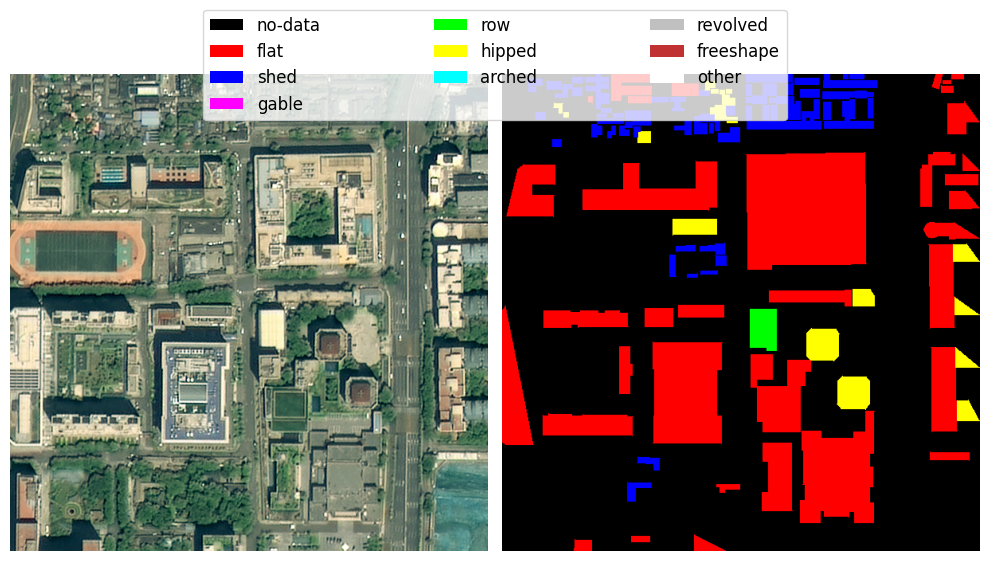

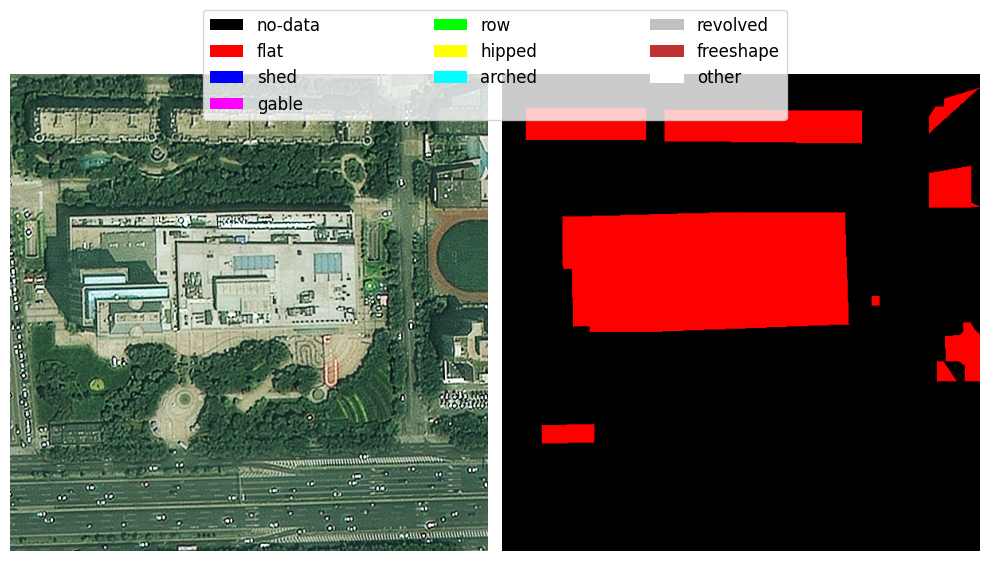

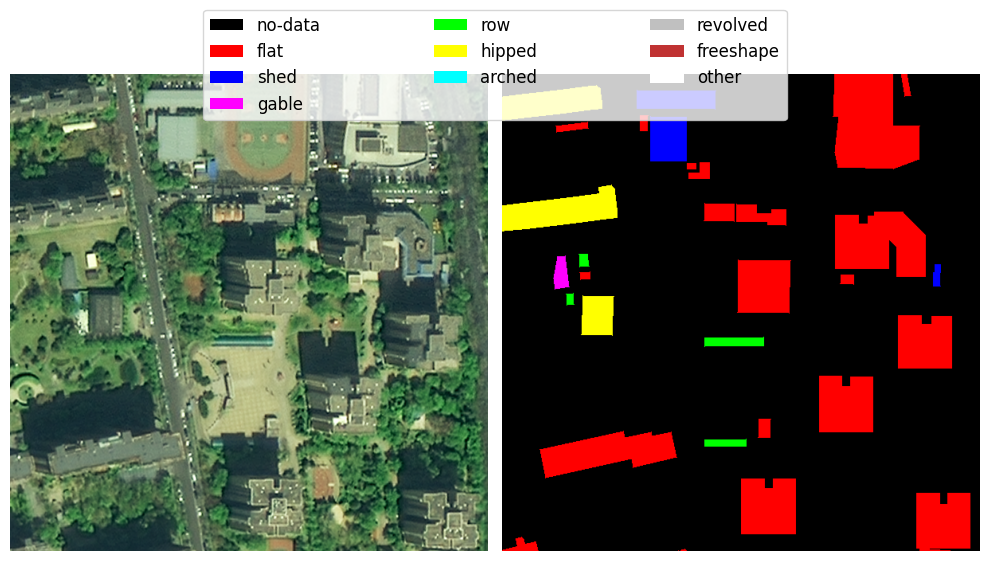

In [58]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200)

## Inspect the data

In [67]:
dataset.data_distribution_table()

,Number of pixels
no-data,148293712.0
flat,28852642.0
shed,11127606.0
gable,6010125.0
row,284271.0
hipped,7031644.0
arched,0.0
revolved,0.0
freeshape,0.0
other,0.0


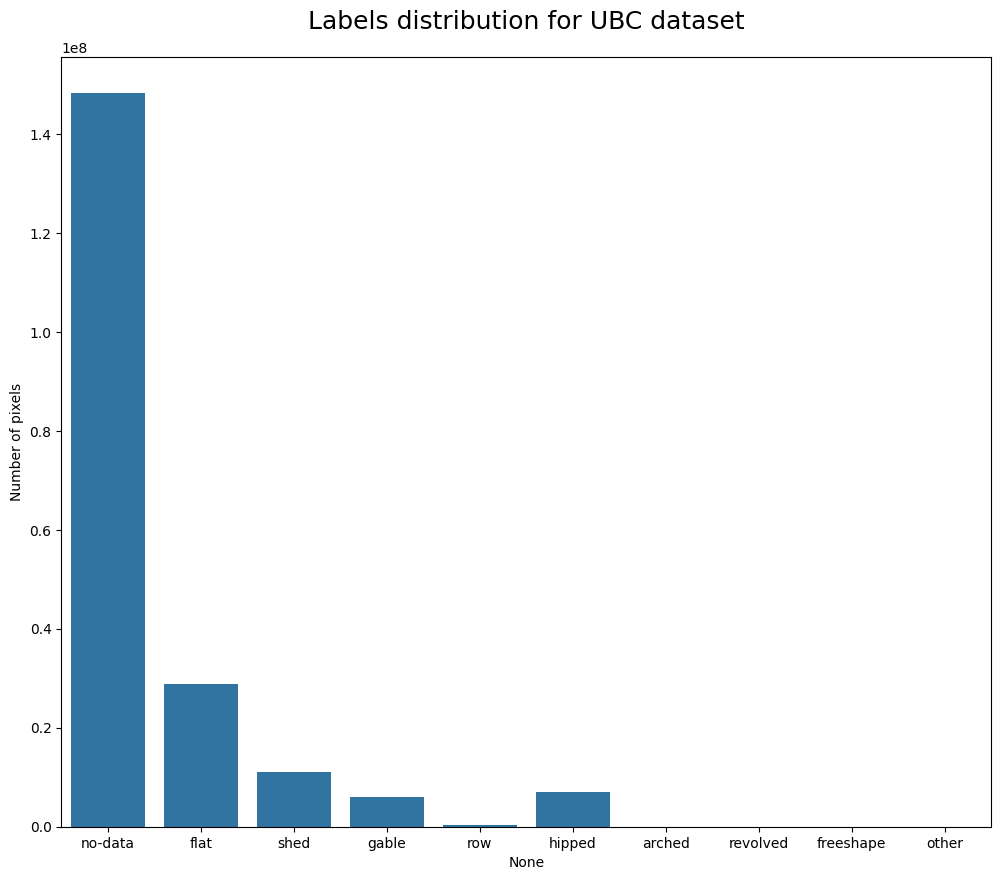

In [68]:
fig = dataset.data_distribution_barchart()

## Load training data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/ubc/train/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/ubc/annotations/roof_coarse_train.json",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = UBCDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 560


## Setup and create the model for training

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/ubc/"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-12 09:22:29,902 INFO Starting training.
training: 100%|██████████| 70/70 [01:06<00:00,  1.05it/s]
2025-11-12 09:23:37,693 INFO epoch: 1, time: 67, loss:  0.76849
testing on train set: 100%|██████████| 70/70 [01:06<00:00,  1.06it/s]
2025-11-12 09:24:46,109 INFO IOU:0.41062857232216265, IOU mean:0.13231188744792005, IOU per Class:[0.75176491 0.26186359 0.14935365 0.0772504  0.         0.08288633
 0.         0.         0.         0.        ]
training: 100%|██████████| 70/70 [01:06<00:00,  1.06it/s]
2025-11-12 09:25:52,453 INFO epoch: 2, time: 66, loss:  0.67613
testing on train set: 100%|██████████| 70/70 [01:07<00:00,  1.04it/s]
2025-11-12 09:26:59,874 INFO IOU:0.5609628866926224, IOU mean:0.1723023045382956, IOU per Class:[0.79144461 0.29202687 0.19241439 0.14363951 0.         0.30349767
 0.         0.         0.         0.        ]
training: 100%|██████████| 70/70 [01:11<00:00,  1.03s/it]
2025-11-12 09:28:11,741 INFO epoch: 3, time: 72, loss:  0.56641
testing on train set: 100%

## Evaluate the model

In [8]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/ubc/val/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/ubc/annotations/roof_coarse_val.json",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}

test_dataset = UBCDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/ubc/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 160


2025-11-12 10:03:56,726 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ubc/checkpoint.pth.tar
2025-11-12 10:03:59,991 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ubc/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 20/20 [00:08<00:00,  2.32it/s]


[{'IOU': 0.7141878410528352,
  'IOU mean': 0.170664491104974,
  'IOU per Class': array([0.82242884, 0.49348425, 0.26278122, 0.        , 0.        ,
         0.1279506 , 0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-11-12 10:06:05,534 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ubc/checkpoint.pth.tar
2025-11-12 10:06:07,922 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ubc/checkpoint.pth.tar at epoch 11


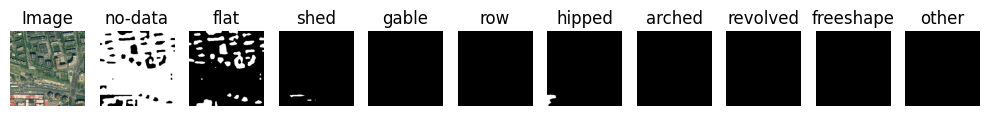

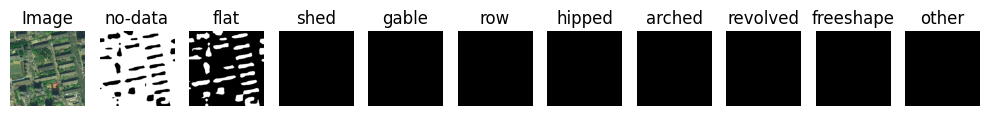

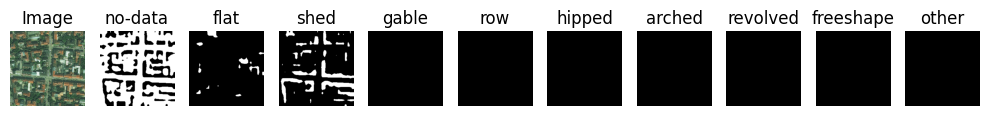

In [12]:
model_path = "/home/dragik/data/FAIR_EO/experiments/ubc/checkpoint.pth.tar"
labels = ["no-data","flat","shed","gable","row","hipped","arched","revolved","freeshape","other"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/ubc/val/Beijing_GF2_L1A0004822322-MSS1_8100_12600_116.2741_39.9347_RGB.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/ubc/val/Beijing_SV1-02_L2A0001092309_10800_5400_116.3379_39.9547_RGB.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/ubc/val/Munich_SV1-03_L2A0001092311_7600_5400_11.5748_48.1620_RGB.tif')
fig = model.predict_masks(image, labels, transform)